In [ ]:
# Estimating gain from responses

In [13]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/BWM

/Users/cl1704/PycharmProjects/embedding_dimension/BWM


In [14]:
import umap

In [15]:
import tensorflow

In [16]:
from matplotlib import gridspec
import matplotlib.pyplot as plt
import seaborn as sns
from iblatlas.regions import BrainRegions
br = BrainRegions()
#from umap.parametric_umap import ParametricUMAP
from iblatlas.regions import BrainRegions
br = BrainRegions()

from bwm_functions import *


In [17]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import torch
import random
import string
import os
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from iblatlas.regions import BrainRegions

br = BrainRegions()
from scipy.sparse import save_npz, load_npz, csr_matrix

# task_id = int(os.environ['SLURM_ARRAY_TASK_ID'])

from bwm_functions import *

# MAIN LOOP
device = 'cpu'

# Get a list of all items (files and folders) in the directory

directory_path = 'Data2'
all_items = os.listdir(directory_path)
print(len(all_items))
# Filter the list to include only folders (directories)
folders_only = [item for item in all_items if os.path.isdir(os.path.join(directory_path, item))]
# eids = np.load("eids.npy",allow_pickle=True)

460


In [18]:
eid = random.choice(folders_only)

In [19]:
#eid = '810b1e07-009e-4ebe-930a-915e4cd8ece4'
#eid = 'c728f6fd-58e2-448d-aefb-a72c637b604c'
#eid = random.choice(folders_only)
full_path_to_random_folder = os.path.join(directory_path, eid)
print(f"Randomly selected eid: {full_path_to_random_folder}")
# Hyperparameters
dim = 10
sample_size = 50
sigma = 10
n_steps = 100
threshold = .01

min_trials_per_condition = 50
# Check if any folders were found

# Select a random folder name from the list

event = random.choice(["firstMovement_times", "feedback_times", "stimOn_times", "response_times"])
conditions = list(np.random.choice(["choice", "prev_choice", "side", "prev_side", "reward", "prev_reward"],
                                   size=np.random.choice([1, 2, 3]), replace=False))
conditions = ['choice']
event = "stimOn_times"

Randomly selected eid: Data2/a1782f4f-86b0-480c-a7f2-3d8f1ab482ab


In [8]:

clusters = pd.read_pickle(full_path_to_random_folder + '/clusters.pkl')

clusters['cosmos'] = br.id2acronym(clusters['atlas_id'], mapping="Cosmos")

spikes = pd.read_pickle(full_path_to_random_folder + '/spikes.pkl')
trials = pd.read_pickle(full_path_to_random_folder + '/trials.pkl')

counts_series = clusters.groupby('cosmos').size()
print(counts_series)

# shape n_pseudo x n_conditions x time x n
response_matrix_train, condition_matrix_train = get_aligned_response_matrix(
    spikes, clusters, trials, event, conditions,
    stride=.005,
    step=.005,
    n_steps=n_steps,
    sigma=sigma,
    threshold=threshold,
    min_trials_per_condition=min_trials_per_condition,regions = counts_series.index.values)

# Restrict to active units
restriction = np.logical_and(np.std(response_matrix_train, axis=(0, 1, 2)) > .01,
                             np.std(response_matrix_train, axis=(0, 1, 2)) > .01)
response_matrix_train = response_matrix_train[
    :, :, :, restriction]

print(response_matrix_train.shape)

n_conditions = response_matrix_train.shape[1]
# Z-score single neuron responses
# response_matrix_train = (response_matrix_train - np.mean(response_matrix_train, axis=(0, 1, 2),
#                                                          keepdims=True)) / np.std(response_matrix_train,
#                                                                                   axis=(0, 1, 2),
#                                                                                   keepdims=True)


cosmos
HB    559
MB    542
dtype: int64
(500, 2, 100, 1091)


In [9]:
np.save('response_matrix_train.npy',response_matrix_train)
np.save('condition_matrix_train.npy',condition_matrix_train)

In [13]:
pwd

'/Users/cl1704/PycharmProjects/embedding_dimension/BWM'

In [ ]:
response_matrix_train.shape

NameError: name 'data' is not defined

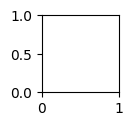

In [8]:
# var = np.var(response_matrix_train,axis = 0)
# mu = np.mean(response_matrix_train,axis = (0,1,2))
#data =np.mean(np.std(response_matrix_train, axis=0), axis=(0, 1))


fig = plt.figure(figsize=(1,1))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.histplot(x = data,color='k',stat = 'probability')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.xaxis.set_tick_params(labelsize=5, bottom=True)
ax.yaxis.set_tick_params(labelsize=5, left=True)
ax.set_ylim(0,.2)
plt.savefig('Figures/Figure_1_b.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)
ax.spines['left'].set_visible(False)
# ax.spines['bottom'].set_visible(False)
# ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_gain_dist.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)

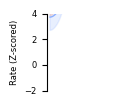

In [87]:
neuron = np.argsort(data)[400]
rows = []
for condition in range(response_matrix_train.shape[1]):
    for trial in range(response_matrix_train.shape[0]):
        for t in range(response_matrix_train.shape[2]):
            rows.append({'condition': condition,
                         'trial': trial,
                         't':t,
                         'x': response_matrix_train[trial, condition, t, neuron].item(),})
df = pd.DataFrame(rows)
fig = plt.figure(figsize=(1,1))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.lineplot(data = df[df.condition ==0], x='t', y='x',errorbar = 'sd',ax=ax,legend=False,lw=1,color=sns.color_palette("coolwarm",n_colors =3)[0])
sns.lineplot(data = df[df.condition ==1], x='t', y='x',errorbar = 'sd',ax=ax,legend=False,lw=1,color=sns.color_palette("coolwarm",n_colors =3)[2])

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.xaxis.set_tick_params(labelsize=6, bottom=True)
ax.yaxis.set_tick_params(labelsize=6, left=True)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(True)
ax.set_ylim(-2,4)
ax.set_ylabel("Rate (Z-scored)",size = 6)
ax.set_xlabel("Time from stim",size = 6)
plt.savefig('Figures/Figure_1_2.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)


In [ ]:
import umap

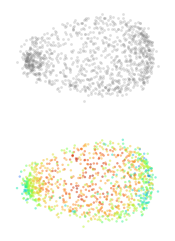

In [11]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.manifold import Isomap
from umap.parametric_umap import ParametricUMAP

from sklearn.manifold import TSNE
fig = plt.figure(figsize=(2,3))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(2,1)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[1,0])


##############################################################################################
######################### Strategy 1 ######################################################
# responses = (response_matrix_train - np.mean(response_matrix_train, axis=(0, 1, 2),
#                                                          keepdims=True)) / np.std(response_matrix_train,
#                                                                                   axis=(0, 1, 2),
#                                                                                   keepdims=True)
# data =np.mean(np.std(responses, axis=0), axis=(0, 1))
# responses = np.mean(responses, axis=0)
# response_matrix = responses.reshape(-1, responses.shape[2])
##############################################################################################
##############################################################################################


##############################################################################################
######################### Strategy 2 ######################################################
responses = (response_matrix_train - np.mean(response_matrix_train, axis=(0, 1, 2),
                                                         keepdims=True)) / np.std(response_matrix_train,
                                                                                  axis=(0, 1, 2),
                                                                                  keepdims=True)
data =np.mean(np.std(responses, axis=0), axis=(0, 1))
responses = np.mean(responses, axis=0)
response_matrix = responses.reshape(-1, responses.shape[2])
##############################################################################################
##############################################################################################


######################### Strategy 2 ######################################################
# responses = (response_matrix_train - np.mean(response_matrix_train, axis=(0, 1, 2),
#                                                          keepdims=True)) / np.std(response_matrix_train,
#                                                                                   axis=(0, 1, 2),
#                                                                                   keepdims=True)
# data =np.mean(np.std(responses, axis=1), axis=(0, 1))
# responses = np.mean(responses, axis=0)
# response_matrix = responses.reshape(-1, responses.shape[2])
##############################################################################################


######################### Strategy 3 ######################################################
# responses = np.mean(response_matrix_train, axis=0)
# responses = (responses - np.mean(responses, axis=(0,1)))/np.std(responses, axis=(0,1))
#
# #responses = np.mean(responses, axis=0)
# response_matrix = responses.reshape(-1, responses.shape[2])
# z = (response_matrix_train - np.mean(response_matrix_train, axis=(0, 1, 2),
#                                                          keepdims=True)) / np.std(response_matrix_train,
#                                                                                   axis=(0, 1, 2),
#                                                                                   keepdims=True)
# data =np.mean(np.std(z, axis=0), axis=(0, 1))
##############################################################################################

############ Z-score means, compute std , compute mean responses ##################################
# responses = (response_matrix_train - np.mean(response_matrix_train, axis=(0, 1, 2),
#                                                          keepdims=True)) / np.std(response_matrix_train,
#                                                                                   axis=(0, 1, 2),
#                                                                                   keepdims=True)
# data =np.mean(np.std(responses, axis=0), axis=(0, 1))
# responses  = np.mean(responses, axis = 0)
# responses = responses.reshape(-1, responses.shape[2])
##############################################################################################


############## Z-score single trials #########################
# data = np.std(response_matrix_train, axis = (0,1,2))
# responses = (response_matrix_train - np.mean(response_matrix_train, axis=(0, 1, 2),
#                                                          keepdims=True)) / np.std(response_matrix_train,
#                                                                                   axis=(0, 1, 2),
#                                                                                   keepdims=True)
# responses = np.mean(responses, axis=0)
# responses = responses.reshape(-1, responses.shape[2])
###############################################################################################

#responses = (np.mean(response_matrix_train, axis=0).reshape(-1,response_matrix_train.shape[3]))
#responses = response_matrix.reshape(-1, response_matrix.shape[2])

#x_proj = Isomap(n_components = 3).fit_transform(response_matrix.T)

x_proj = TSNE(n_components = 2,perplexity = 400).fit_transform(response_matrix.T)
from sklearn.manifold import Isomap
# response_matrix = (response_matrix - response_matrix.min())/(response_matrix.max()-response_matrix.min())
# umap = ParametricUMAP(
#     parametric_reconstruction= True,
#     autoencoder_loss = True,
#     verbose=True,
#     densmap=True,
#     n_components = 2
# )
# import umap
# fit = umap.UMAP(densmap=True,dens_lambda =20)
# x_proj= fit.fit_transform(response_matrix.T)

sns.scatterplot(x=x_proj[:,0], y=x_proj[:,1],s=4,ax=ax0,legend = False,lw = 0,alpha = .25,color='gray')
#sns.kdeplot(x=x_proj[:,0], y=x_proj[:,1],ax=ax0,legend = False,lw = 0,alpha = .5,cmap = 'turbo_r',fill=True,levels = 100)
#sns.histplot(x=x_proj[:,0], y=x_proj[:,1],ax=ax0,legend = False,lw = 0,alpha = .5,cmap = 'turbo_r',bins = 20)
#responses = np.mean(response_matrix_train, axis=0).reshape(-1,response_matrix_train.shape[3])

# pca = PCA(n_components = 3)
# pca.fit(responses[:,data<.2].T)
#x_proj = pca.transform(responses.T)
sns.scatterplot(x=x_proj[:,0], y=x_proj[:,1],s=3,ax=ax1,legend = False,lw = 0,alpha = .5,hue = data,palette = 'turbo',hue_norm = (0,1))


#ax1.tricontourf(x_proj[:,0], x_proj[:,1], data, levels=10, cmap='turbo',alpha = .6)
# responses = np.mean(response_matrix_train, axis=0).reshape(-1,response_matrix_train.shape[3])
# responses = responses[:,data<.2]
# pca = PCA(n_components = 3)
# pca.fit(responses.T)
# x_proj = pca.transform(responses.T)


for ax in [ax0,ax1]:
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.axes.get_xaxis().set_visible(False)
    ax.axes.get_yaxis().set_visible(False)
    ax.set_aspect('equal')
plt.savefig('Figures/Figure_1_b.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)


In [12]:
response_matrix.shape

(200, 1091)

In [69]:
import skdim
X = response_matrix.T
X = X[data<.3,:]
# Use the DANCo estimator (very robust)
estimator = skdim.id.DANCo().fit(X)
print(f"Intrinsic Dimension: {estimator.dimension_}")

# Or the Levina-Bickel version
estimator = skdim.id.MLE().fit(X)
print(f"Intrinsic Dimension: {estimator.dimension_}")

Intrinsic Dimension: 6.171301009328745
Intrinsic Dimension: 3.839815987648906


In [ ]:
%%sql


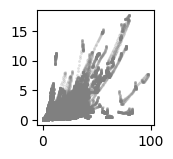

In [83]:
###########################################################################
######################## Variance as a function of state ##################
###########################################################################
fig = plt.figure(figsize=(1.5,1.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])

for neuron in range(2300):
    var = np.var(response_matrix_train[:,:,:,neuron],axis=0).flatten()
    rate = np.mean(response_matrix_train[:,:,:,neuron],axis=0).flatten()
    sns.scatterplot(x = rate, y = var,ax=ax,color='gray',lw=0,s = 4,alpha = .25)



In [71]:
response_matrix_train.shape

(500, 2, 100, 2373)

In [60]:
X.shape

(2373, 200)

In [85]:
import numpy as np

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.express as px


fig = make_subplots(
     rows=1, cols=1,
     specs=[[{"type": "scene"}]])


fig.add_trace(go.Scatter3d(x=x_proj[:,0],
                          y=x_proj[:,1],
                          z=x_proj[:,2],
                              mode='markers',

                        marker=dict(
                            color=data,
                            colorscale='turbo',
                            opacity=.5,
                            size = 3
                        )), row=1, col=1)
#px.colors.diverging.balance
#
fig.update_layout( scene = dict(xaxis = dict(showgrid = False,showticklabels = False),
                                   yaxis = dict(showgrid = False,showticklabels = False),
                                   zaxis = dict(showgrid = False,showticklabels = False),

             ))
fig.update_scenes(xaxis_visible=False, yaxis_visible=False,zaxis_visible=False )

In [ ]:
plt.figure()
sns.histplot(x =data)


In [116]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class DistancePreservingAE(nn.Module):
    def __init__(self, input_dim, latent_dim):
        super(DistancePreservingAE, self).__init__()

        # Encoder: Compressing data
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.Tanh(),
            nn.Linear(64, latent_dim)
        )

        # Decoder: Reconstructing data
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.Tanh(),
            nn.Linear(64, input_dim)
        )

    def forward(self, x):
        z = self.encoder(x)
        x_recon = self.decoder(z)
        return x_recon, z

def distance_loss(x, z, k=10):
    """
    Computes a loss term that penalizes distance changes between neighbors.
    """
    # 1. Compute pairwise distances in input space
    dist_x = torch.cdist(x, x, p=2)

    # 2. Find indices of k-nearest neighbors for each point
    _, knn_indices = torch.topk(dist_x, k=k+1, largest=False)

    # 3. Compute pairwise distances in latent space
    dist_z = torch.cdist(z, z, p=2)

    # 4. Sum distances in latent space for those who were neighbors in X
    # We ignore the first neighbor (index 0) because it's the point itself.
    local_loss = 0
    for i in range(1, k + 1):
        neighbor_indices = knn_indices[:, i]
        # Gather latent distances between point i and its j-th neighbor
        local_loss += torch.mean(dist_z[torch.arange(z.size(0)), neighbor_indices])

    return local_loss

# --- Hyperparameters and Training Setup ---
input_size = 300  # Example for flattened MNIST
latent_size = 3
model = DistancePreservingAE(input_size, latent_size)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# Training Loop snippet
def train_step(model, data, alpha=1):
    optimizer.zero_grad()

    # Forward pass
    reconstruction, latent = model(data)

    # Loss 1: Reconstruction (Standard AE)
    recon_loss = F.mse_loss(reconstruction, data)

    # Loss 2: Distance Preservation (Isometric constraint)
    dist_pres_loss = distance_loss(data, latent)

    # Total Loss: Balanced by hyperparameter alpha
    total_loss = recon_loss + (alpha * dist_pres_loss)

    total_loss.backward()
    optimizer.step()

    return total_loss.item()

training_data = torch.tensor(response_matrix.T).float()
for i in range(1000):
    loss = train_step(model, training_data, alpha=.1)
    print(loss)

In [117]:
training_data = torch.tensor(response_matrix.T).float()
for i in range(1000):
    loss = train_step(model, training_data, alpha=.1)
    print(loss)

0.9429574012756348
0.8543277978897095
0.8225599527359009
0.8232360482215881
0.8158144354820251
0.7989842891693115
0.7803181409835815
0.766851007938385
0.7602123618125916
0.7551887035369873
0.7473946809768677
0.7380743026733398
0.730716347694397
0.7265662550926208
0.7229982614517212
0.7178953289985657
0.7125769257545471
0.7090237140655518
0.7064535617828369
0.7031767964363098
0.6997275352478027
0.6977722644805908
0.6960015892982483
0.6935888528823853
0.6912877559661865
0.6901423931121826
0.6882873773574829
0.6866532564163208
0.6860897541046143
0.6854408383369446
0.6834158897399902
0.681759774684906
0.6820921301841736
0.6816369891166687
0.6797139048576355
0.6785166263580322
0.6792147159576416
0.6784403920173645
0.6771315336227417
0.6771490573883057
0.6785745024681091
0.6769338250160217
0.675569474697113
0.6761443018913269
0.6753810048103333
0.6741946339607239
0.6739071607589722
0.6738399863243103
0.6747530698776245
0.6733553409576416
0.6726341247558594
0.6729361414909363
0.67223542928695

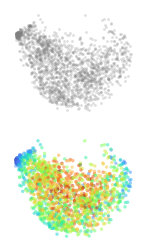

In [118]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.manifold import Isomap
from umap.parametric_umap import ParametricUMAP

from sklearn.manifold import TSNE
fig = plt.figure(figsize=(2,3))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(2,1)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[1,0])



x_proj = model.encoder(training_data).detach().numpy()
sns.scatterplot(x=x_proj[:,0], y=x_proj[:,1],s=4,ax=ax0,legend = False,lw = 0,alpha = .25,color='gray')
#sns.kdeplot(x=x_proj[:,0], y=x_proj[:,1],ax=ax0,legend = False,lw = 0,alpha = .5,cmap = 'turbo_r',fill=True,levels = 100)
#sns.histplot(x=x_proj[:,0], y=x_proj[:,1],ax=ax0,legend = False,lw = 0,alpha = .5,cmap = 'turbo_r',bins = 20)
#responses = np.mean(response_matrix_train, axis=0).reshape(-1,response_matrix_train.shape[3])

# pca = PCA(n_components = 3)
# pca.fit(responses[:,data<.2].T)
#x_proj = pca.transform(responses.T)
sns.scatterplot(x=x_proj[:,0], y=x_proj[:,1],s=6,ax=ax1,legend = False,lw = 0,alpha = .5,hue = data,palette = 'turbo')


#ax1.tricontourf(x_proj[:,0], x_proj[:,1], data, levels=10, cmap='turbo',alpha = .6)
# responses = np.mean(response_matrix_train, axis=0).reshape(-1,response_matrix_train.shape[3])
# responses = responses[:,data<.2]
# pca = PCA(n_components = 3)
# pca.fit(responses.T)
# x_proj = pca.transform(responses.T)


for ax in [ax0,ax1]:
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.axes.get_xaxis().set_visible(False)
    ax.axes.get_yaxis().set_visible(False)
    ax.set_aspect('equal')
plt.savefig('Figures/Figure_1_b.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)


In [ ]:
# Lolca preserving

In [ ]:
pseudo_responses.shape

In [ ]:
pseudo_responses = pseudo_responses.transpose(1,2,3,0)

In [ ]:
pseudo_responses.shape

In [ ]:
pseudo_responses = pseudo_responses.reshape(-1, pseudo_responses.shape[2], pseudo_responses.shape[3])

In [ ]:
pseudo_responses.shape


In [ ]:
pseudo_responses = pseudo_responses.reshape(pseudo_responses.shape[0], -1)

In [ ]:
pseudo_responses.shape

<Figure size 640x480 with 0 Axes>

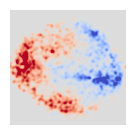

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.animation import FuncAnimation
from scipy.ndimage import gaussian_filter
from sklearn.manifold import Isomap
from sklearn.manifold import TSNE

#mean_responses = np.mean(response_matrix_train, axis=0)
# mean_responses = responses
# pca = TSNE(n_components = 2)
#
# x_proj = pca.fit_transform(responses.T)

embedding =(70*x_proj[:,:2]).astype(int) - (70*x_proj[:,:2]).astype(int).min()
def spatial_embedding(response,embedding,sigma):
    m = np.zeros((embedding.max()+1,embedding.max()+1))
    for neuron in range(embedding.shape[0]):
        m[embedding[neuron,1],embedding[neuron,0]] = response[neuron]
    m = np.flipud(m)
    return gaussian_filter(m,sigma)

t = 90
sigma = 10
vmin = -.01
vmax = .01
m = spatial_embedding(responses[0,t,:],embedding,sigma=sigma)
plt.figure()
from scipy.ndimage import gaussian_filter
fig = plt.figure(figsize=(1.5,1.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.heatmap(m ,vmin =vmin,vmax = vmax,cbar = False,ax=ax,cmap = 'coolwarm', center=0)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)

plt.savefig('Figures/Figure_1_'+str(t)+'.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)


In [ ]:
eid

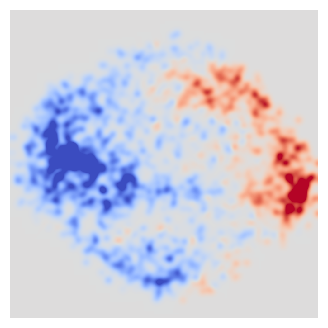

In [26]:
num_frames = responses.shape[1]
trial =1

data_list = [spatial_embedding(responses[trial,i,:],embedding,sigma)  for i in range(num_frames)]

# 2. Set up the figure and axes
fig, ax = plt.subplots(figsize=(4,4))

# Set consistent colorbar range (vmin/vmax) if desired, for smooth animation


def update(frame_num):
    """Updates the heatmap for each frame of the animation."""
    ax.clear()  # Clear the previous frame's axis
    current_data = data_list[frame_num]
    sns.heatmap(current_data, ax=ax, cbar=False, vmin=vmin, vmax=vmax,center=0,cmap = 'coolwarm')
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.axes.get_xaxis().set_visible(False)
    ax.axes.get_yaxis().set_visible(False)
    ax.set_aspect('equal')
anim = FuncAnimation(fig, update, frames=num_frames, interval=200, blit=False)
try:
    os.makedirs("Movies/" + eid)
except:
    pass
anim.save('Movies/' + eid +'/' +'trial_'+str(trial) + ".mp4", writer='ffmpeg', fps=5)

In [25]:
eid

'e2b845a1-e313-4a08-bc61-a5f662ed295e'

In [ ]:
np.save('x_proj.npy',x_proj)

In [ ]:
##########################################################
################## Neural Manifold #######################
##########################################################

fig = plt.figure(figsize=(2.5,2.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
mean_responses = np.mean(response_matrix_train,axis=0)
pca = PCA().fit(mean_responses.reshape(-1,mean_responses.shape[2]))
# for c in range(response_matrix_train.shape[1]):
#     x_proj = pca.transform(np.mean(response_matrix_train[:,c,:,:],axis=0))
#     ax.plot(x_proj[:,2], x_proj[:,1],lw = 1,color ='gray',alpha = 1)


for c in range(response_matrix_train.shape[1]):
    for k in range(100):
        x_proj = pca.transform(response_matrix_train[k,c,:,:])
        ax.plot(x_proj[:,1], x_proj[:,2],lw = .25,color =sns.color_palette('coolwarm',n_colors=2)[c],alpha = 1)

        x_proj = pca.transform(np.mean(response_matrix_train[:,0,:,:],axis=0))
ax.plot(x_proj[:,1], x_proj[:,2],lw = 1,color ='gray',alpha = 1,marker = '.',markevery = 10)

x_proj = pca.transform(np.mean(response_matrix_train[:,1,:,:],axis=0))
ax.plot(x_proj[:,1], x_proj[:,2],lw = .5,color ='gray',alpha = 1,marker = '.',markevery = 10)

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_1_b.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)



In [ ]:
# Dimensionality




pca = PCA().fit(mean_responses.reshape(-1,mean_responses.shape[2]))
fig = plt.figure(figsize=(1.25, 1.25))
from scipy.spatial import ConvexHull

gs = gridspec.GridSpec(1, 1)

ax = fig.add_subplot(gs[0, 0])
sns.barplot(x = np.arange(1,15),y = pca.explained_variance_ratio_[:14],color='black')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

ax.xaxis.set_tick_params(labelsize=6, bottom=True)
ax.yaxis.set_tick_params(labelsize=6, left=True)
ax.axes.get_xaxis().set_visible(False)

ax.set_ylim(0,.5)
plt.savefig('Figures/Figure_1_d.jpg',
            format='jpeg',

            dpi=450,
            bbox_inches='tight', transparent=True)


In [ ]:
mean_responses.shape

In [ ]:
response_matrix_train.shape


In [ ]:
x_proj.shape

In [ ]:
# 1. Load in spikesorting data for pid
from brainbox.io.one import SpikeSortingLoader
from one.api import ONE
from iblatlas.atlas import AllenAtlas
import numpy as np

ba = AllenAtlas()
one = ONE()
pid = eid

ssl = SpikeSortingLoader(one=one, eid=pid, atlas=ba)
spikes, clusters, channels = ssl.load_spike_sorting()
clusters = ssl.merge_clusters(spikes, clusters, channels)
# 2. Evaluate the number of good clusters
# The spikesortingloader loads data for all clusters (both mua and good) detected by the spikesorter.
# We can restrict to only the good clusters by finding the clusters with a label of 1
good_cluster_idx = clusters['label'] == 1
clusters_good = {key:val[good_cluster_idx] for key, val in clusters.items()}

all_clusters = clusters['label'].shape
good_clusters = clusters_good['label'].shape
print(f'Total no. of clusters: {all_clusters}')
print(f'Number of good clusters: {good_clusters}')
# 4. Compute the firing rate of each cluster
# The firing rate of each cluster can be found in the firing rate atrribute of the clusters object
firing_rate = clusters_good['firing_rate']

# To show the interaction between the clusters and the spikes object we will show how you can compute
# the firing rate from the data

# To compute the firing rate we first need to compute the number of spikes detected for each cluster
n_spikes = np.empty((clusters_good['cluster_id'].shape))
# Loop over the cluster ids
for i, c in enumerate(clusters_good['cluster_id']):
  # Find location where each cluster id is found in the spikes objects and get the sum
  cidx = np.sum(spikes['clusters'] == c)
  n_spikes[i] = cidx

# To compute the firing rate we can divide the spike count by the total duration of the recording
duration = np.max(spikes['times']) - np.min(spikes['times'])
firing_rate_from_spikes = n_spikes / duration

# Make sure that the values for firing rates are the same
np.array_equal(firing_rate_from_spikes, firing_rate)

In [ ]:
# 1. Load in spikesorting data for pid
from brainbox.io.one import SpikeSortingLoader
from one.api import ONE
from iblatlas.atlas import AllenAtlas
import numpy as np

ba = AllenAtlas()
one = ONE()
pid = eid

ssl = SpikeSortingLoader(one=one, eid=pid, atlas=ba)
spikes, clusters, channels = ssl.load_spike_sorting()
clusters = ssl.merge_clusters(spikes, clusters, channels)
# 2. Evaluate the number of good clusters
# The spikesortingloader loads data for all clusters (both mua and good) detected by the spikesorter.
# We can restrict to only the good clusters by finding the clusters with a label of 1
good_cluster_idx = clusters['label'] == 1
clusters_good = {key:val[good_cluster_idx] for key, val in clusters.items()}

all_clusters = clusters['label'].shape
good_clusters = clusters_good['label'].shape
print(f'Total no. of clusters: {all_clusters}')
print(f'Number of good clusters: {good_clusters}')
# 4. Compute the firing rate of each cluster
# The firing rate of each cluster can be found in the firing rate atrribute of the clusters object
firing_rate = clusters_good['firing_rate']

# To show the interaction between the clusters and the spikes object we will show how you can compute
# the firing rate from the data

# To compute the firing rate we first need to compute the number of spikes detected for each cluster
n_spikes = np.empty((clusters_good['cluster_id'].shape))
# Loop over the cluster ids
for i, c in enumerate(clusters_good['cluster_id']):
  # Find location where each cluster id is found in the spikes objects and get the sum
  cidx = np.sum(spikes['clusters'] == c)
  n_spikes[i] = cidx

# To compute the firing rate we can divide the spike count by the total duration of the recording
duration = np.max(spikes['times']) - np.min(spikes['times'])
firing_rate_from_spikes = n_spikes / duration

# Make sure that the values for firing rates are the same
np.array_equal(firing_rate_from_spikes, firing_rate)
# 5. Plot firing rate and brain locations
import matplotlib.pyplot as plt
from matplotlib import colors, cm, colormaps
from brainbox.ephys_plots import plot_brain_regions
clusters_good.keys()

norm = colors.Normalize(vmin=np.min(firing_rate), vmax=np.max(firing_rate), clip=True)
mapper = cm.ScalarMappable(norm=norm, cmap=colormaps.get_cmap('hot'))
firing_rate_cols = mapper.to_rgba(firing_rate)

fig, axs = plt.subplots(1, 2)
# Plot the brain regions through which the channels on the insertion pass
plot_brain_regions(channels['atlas_id'], channel_depths=channels['axial_um'], ax=axs[0])
# Plot scatter plot of cluster depths vs cluster amp with firing rate encoded in colour
# Map firing rate values to colours
norm = colors.Normalize(vmin=np.min(firing_rate), vmax=np.max(firing_rate), clip=True)
mapper = cm.ScalarMappable(norm=norm, cmap=colormaps.get_cmap('hot'))
firing_rate_cols = mapper.to_rgba(firing_rate)
axs[1].scatter(clusters_good['amp_median'] * 1e6, clusters_good['depths'], c=firing_rate_cols)
axs[1].set_xlabel('Amps (uV)')
axs[1].get_yaxis().set_visible(False)
# Add colorbar
cbar = fig.colorbar(mapper, ax=axs[1])
cbar.set_label('Firing rate (Hz)')
plt.savefig('Figures/Figure_1_b.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)

In [ ]:
responses